El valor interpolado en x = 3 es y = 4.0


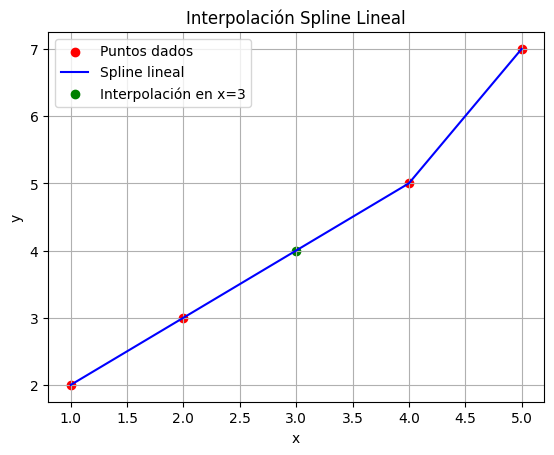

In [ ]:
#spline lineal
import numpy as np
import matplotlib.pyplot as plt

# Función para calcular las pendientes y los interceptos
def spline_lineal(x_vals, y_vals, x_interp):
    n = len(x_vals) - 1
    a_vals = []  # Pendientes
    b_vals = []  # Interceptos

    for i in range(n):
        # Calcular pendiente a_i
        a_i = (y_vals[i+1] - y_vals[i]) / (x_vals[i+1] - x_vals[i])
        # Calcular intercepto b_i
        b_i = y_vals[i] - a_i * x_vals[i]
        a_vals.append(a_i)
        b_vals.append(b_i)

    # Determinar en qué intervalo está el punto a interpolar
    for i in range(n):
        if x_vals[i] <= x_interp <= x_vals[i+1]:
            y_interp = a_vals[i] * x_interp + b_vals[i]
            return y_interp, a_vals, b_vals

    return None, a_vals, b_vals  # Si el punto está fuera del rango

# Datos de ejemplo (puedes modificarlos)
x_vals = [1, 2, 4, 5]  # Valores de x
y_vals = [2, 3, 5, 7]  # Valores de y correspondientes
x_interp = 3  # Valor de x que deseas interpolar

# Calcular la interpolación
y_interp, a_vals, b_vals = spline_lineal(x_vals, y_vals, x_interp)

# Mostrar el resultado de la interpolación
if y_interp is not None:
    print(f"El valor interpolado en x = {x_interp} es y = {y_interp}")
else:
    print(f"El valor x = {x_interp} está fuera del rango de los puntos dados.")

# Graficar los puntos y la interpolación
plt.scatter(x_vals, y_vals, color='red', label='Puntos dados')
plt.plot(x_vals, y_vals, label='Spline lineal', color='blue')

# Graficar el punto interpolado si está dentro del rango
if y_interp is not None:
    plt.scatter(x_interp, y_interp, color='green', label=f'Interpolación en x={x_interp}')

plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('Interpolación Spline Lineal')
plt.grid(True)
plt.show()


Introduce el número de puntos: 5
Introduce el valor de x0: 1.6
Introduce el valor de y0: 2
Introduce el valor de x1: 2
Introduce el valor de y1: 8
Introduce el valor de x2: 2.5
Introduce el valor de y2: 14
Introduce el valor de x3: 3.2
Introduce el valor de y3: 15
Introduce el valor de x4: 4
Introduce el valor de y4: 8
Introduce el valor de x que deseas interpolar: 3.4
El valor interpolado en x = 3.4 es y = 12.8125


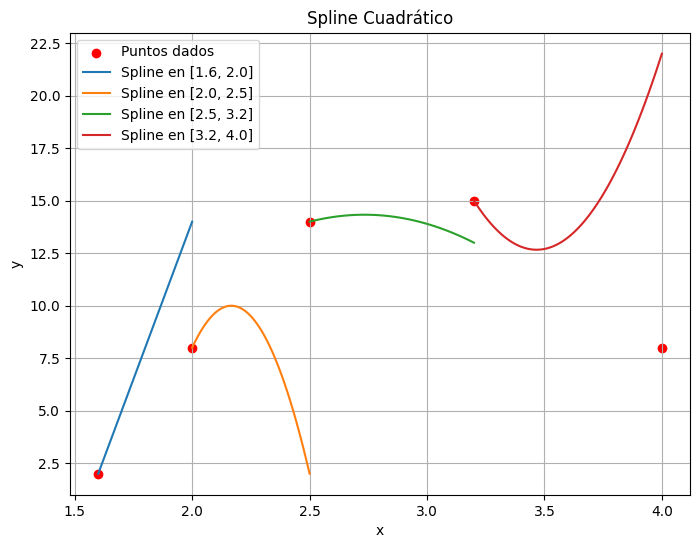

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Funciones para el spline cuadrático
def spline_cuadratico(puntos, x_deseado):
    n = len(puntos) - 1  # Número de intervalos
    splines = []

    # Definimos las splines cuadráticas por cada intervalo
    for i in range(n):
        x0, y0 = puntos[i]
        x1, y1 = puntos[i + 1]

        # Coeficientes para el intervalo
        if i == 0:  # Condición spline natural (derivada segunda es cero en x0)
            a = 0
        else:
            a = -3 * ((y1 - y0) / ((x1 - x0)**2))

        b = 2 * ((y1 - y0) / (x1 - x0))
        c = y0

        # Guardamos los coeficientes de la spline en este intervalo
        splines.append((a, b, c, x0, x1))

    # Interpolación en el valor deseado
    for a, b, c, x0, x1 in splines:
        if x0 <= x_deseado <= x1:
            y_deseado = a * (x_deseado - x0)**2 + b * (x_deseado - x0) + c
            return y_deseado, splines

    raise ValueError("El valor x deseado está fuera del rango de puntos dados.")

# Graficar las splines cuadráticas
def graficar_splines(puntos, splines):
    plt.figure(figsize=(8, 6))

    # Graficamos los puntos
    puntos = np.array(puntos)
    plt.scatter(puntos[:, 0], puntos[:, 1], color='red', label='Puntos dados')

    # Graficamos las funciones spline en cada intervalo
    for a, b, c, x0, x1 in splines:
        x_vals = np.linspace(x0, x1, 100)
        y_vals = a * (x_vals - x0)**2 + b * (x_vals - x0) + c
        plt.plot(x_vals, y_vals, label=f"Spline en [{x0}, {x1}]")

    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Spline Cuadrático')
    plt.legend()
    plt.grid(True)
    plt.show()

# Función principal
def main():
    # Pedir al usuario los puntos
    num_puntos = int(input("Introduce el número de puntos: "))
    puntos = []

    for i in range(num_puntos):
        x = float(input(f"Introduce el valor de x{i}: "))
        y = float(input(f"Introduce el valor de y{i}: "))
        puntos.append((x, y))

    x_deseado = float(input("Introduce el valor de x que deseas interpolar: "))

    # Calcular spline cuadrático e interpolar
    try:
        y_deseado, splines = spline_cuadratico(puntos, x_deseado)
        print(f"El valor interpolado en x = {x_deseado} es y = {y_deseado}")

        # Graficar el spline
        graficar_splines(puntos, splines)
    except ValueError as e:
        print(e)

# Ejecutar el programa
if __name__ == "__main__":
    main()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Función para resolver el sistema de spline cúbico
def cubic_spline(x, y):
    n = len(x) - 1
    h = np.diff(x)

    # Sistema de ecuaciones
    A = np.zeros((n + 1, n + 1))
    rhs = np.zeros(n + 1)

    # Primer y último punto son condiciones de borde (spline natural)
    A[0, 0] = 1
    A[n, n] = 1

    # Llenar el sistema
    for i in range(1, n):
        A[i, i - 1] = h[i - 1] / 6
        A[i, i] = (h[i - 1] + h[i]) / 3
        A[i, i + 1] = h[i] / 6
        rhs[i] = (y[i + 1] - y[i]) / h[i] - (y[i] - y[i - 1]) / h[i - 1]

    # Resolver el sistema
    M = np.linalg.solve(A, rhs)

    # Calcular coeficientes
    a = y[:-1]
    b = np.diff(y) / h - h * (2 * M[:-1] + M[1:]) / 6
    c = M[:-1] / 2
    d = np.diff(M) / h

    return a, b, c, d, h

# Función para calcular el valor del spline
def evaluate_spline(x, a, b, c, d, h, x_val):
    # Encuentra el intervalo correspondiente
    for i in range(len(h)):
        if x_val < x[i + 1]:
            break
    else:
        i = len(h) - 1

    dx = x_val - x[i]
    return a[i] + b[i] * dx + c[i] * dx**2 + d[i] * dx**3

# Solicitar al usuario que ingrese los puntos
n = int(input("Ingrese el número de puntos: "))
x = np.zeros(n)
y = np.zeros(n)

for i in range(n):
    x[i] = float(input(f"Ingrese el valor de x[{i + 1}]: "))
    y[i] = float(input(f"Ingrese el valor de y[{i + 1}]: "))

# Calcular coeficientes del spline
a, b, c, d, h = cubic_spline(x, y)

# Solicitar el valor a interpolar
x_interp_value = float(input("Ingrese el valor de x a interpolar: "))

# Calcular el valor interpolado
y_interp_value = evaluate_spline(x, a, b, c, d, h, x_interp_value)
print(f"El valor interpolado en x = {x_interp_value} es y = {y_interp_value}")

# Generar valores para graficar el spline
x_plot = np.linspace(min(x), max(x), 100)
y_plot = [evaluate_spline(x, a, b, c, d, h, val) for val in x_plot]

# Graficar
plt.scatter(x, y, color='red', label='Puntos originales')
plt.plot(x_plot, y_plot, label='Spline cúbico (manual)', color='blue')
plt.title('Interpolación por Spline Cúbico (Manual)')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid()
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# Solicitar al usuario que ingrese los puntos
n = int(input("Ingrese el número de puntos: "))
x = np.zeros(n)
y = np.zeros(n)

for i in range(n):
    x[i] = float(input(f"Ingrese el valor de x[{i + 1}]: "))
    y[i] = float(input(f"Ingrese el valor de y[{i + 1}]: "))

# Crear el objeto CubicSpline
cs = CubicSpline(x, y)

# Solicitar el valor a interpolar
x_interp_value = float(input("Ingrese el valor de x a interpolar: "))

# Calcular el valor interpolado
y_interp_value = cs(x_interp_value)
print(f"El valor interpolado en x = {x_interp_value} es y = {y_interp_value}")

# Generar valores de x para graficar el spline
x_plot = np.linspace(min(x), max(x), 100)
y_plot = cs(x_plot)

# Graficar
plt.scatter(x, y, color='red', label='Puntos originales')
plt.plot(x_plot, y_plot, label='Spline cúbico', color='blue')
plt.title('Interpolación por Spline Cúbico')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid()
plt.show()
